# **Phase 1 — Metadata Analysis**
# Learning objective


1. Who are the patients?
2. How many patients are there?
3. How are they distributed across disease groups?
4. Are there missing values?
5. Are there duplicate samples?
6. Are there obvious confounders (age, sex, BMI)?

# Dataset Overview

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
metadata = pd.read_csv("data/metadata.tsv", sep="\t")

metadata.head()

,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
0,YACHIDA_CRC_2019,10021,10021,Stage_I_II,57,Years,Male,26.880952,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,I,130,993.0,Left colon,False
1,YACHIDA_CRC_2019,10023,10023,Healthy,65,Years,Male,26.562500,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,660,0.0,-,False
2,YACHIDA_CRC_2019,10025,10025,Healthy,40,Years,Male,25.000000,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,400,993.0,-,True
3,YACHIDA_CRC_2019,10029,10029,Healthy,67,Years,Female,20.173253,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.0,-,False
4,YACHIDA_CRC_2019,10031,10031,Healthy,77,Years,Male,24.464602,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,300,813.0,-,False


In [3]:
print(metadata.shape)

(347, 15)


347 samples, and 15 features

In [4]:
print(metadata.columns)

Index(['Dataset', 'Sample', 'Subject', 'Study.Group', 'Age', 'Age.Units',
       'Gender', 'BMI', 'DOI', 'Publication.Name', 'Stage', 'Brinkman Index',
       'Alcohol', 'Tumor location', 'Shared.w.ERAWIJANTARI_2020'],
      dtype='str')


Intepretation:

**Which column uniquely identifies a patient?** sample and subject

**Which column is the disease label?** study group

**Which variables are continuous?** age bmi Brinkmen index

**Which variables are categorical?** study group, gender, age units, alcohol, tumor location.


In [5]:
metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 347 entries, 0 to 346
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Dataset                     347 non-null    str    
 1   Sample                      347 non-null    int64  
 2   Subject                     347 non-null    int64  
 3   Study.Group                 347 non-null    str    
 4   Age                         347 non-null    int64  
 5   Age.Units                   347 non-null    str    
 6   Gender                      347 non-null    str    
 7   BMI                         347 non-null    float64
 8   DOI                         347 non-null    str    
 9   Publication.Name            347 non-null    str    
 10  Stage                       347 non-null    str    
 11  Brinkman Index              347 non-null    int64  
 12  Alcohol                     347 non-null    float64
 13  Tumor location              347 non-null    st

In [6]:
metadata.describe() #numerical columns

,Sample,Subject,Age,BMI,Brinkman Index,Alcohol
count,347.000000,347.000000,347.000000,347.000000,347.000000,347.000000
mean,10412.737752,10412.737752,63.239193,23.016496,401.930836,248.244073
std,242.378407,242.378407,10.277810,3.192630,526.357102,380.044258
min,10021.000000,10021.000000,28.000000,16.141529,0.000000,0.000000
25%,10214.000000,10214.000000,57.000000,20.819278,0.000000,0.000000
50%,10354.000000,10354.000000,65.000000,22.679952,216.000000,44.200000
75%,10631.000000,10631.000000,71.000000,24.664266,640.000000,360.000000
max,10853.000000,10853.000000,79.000000,37.551020,3200.000000,1953.000000


In [7]:
metadata.describe(include="object") #catgorical columns

/tmp/ipykernel_1012100/3715664720.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  metadata.describe(include="object") #catgorical columns


,Dataset,Study.Group,Age.Units,Gender,DOI,Publication.Name,Stage,Tumor location
count,347,347,347,347,347,347,347,347
unique,1,6,1,2,1,1,12,7
top,YACHIDA_CRC_2019,Healthy,Years,Male,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,-
freq,347,127,347,204,347,347,197,197



The metadata file contains 347 paired samples and 15 clinical variables collected from participants in the Yachida et al. (2019) colorectal cancer study. The variables include demographic information (age, sex, BMI), disease classification (Study.Group and Stage), lifestyle factors (Brinkman Index and Alcohol consumption), tumour location, and sample identifiers. All variables were successfully loaded and will be used for quality control, exploratory data analysis, and integration with the metagenomic and metabolomic datasets.

# Data Quality Summary

In [8]:
# Missing values per column
missing_values = metadata.isna().sum().sort_values(ascending=False)
missing_values

Dataset                       0
Sample                        0
Subject                       0
Study.Group                   0
Age                           0
Age.Units                     0
Gender                        0
BMI                           0
DOI                           0
Publication.Name              0
Stage                         0
Brinkman Index                0
Alcohol                       0
Tumor location                0
Shared.w.ERAWIJANTARI_2020    0
dtype: int64

In [9]:
# Total missing values
metadata.isna().sum().sum()

np.int64(0)

In [10]:
# Duplicate sample IDs
metadata["Sample"].duplicated().sum()

np.int64(0)

In [11]:
# Duplicate subject IDs
metadata["Subject"].duplicated().sum()

np.int64(0)

In [12]:
# Number of unique samples and subjects
print("Unique samples:", metadata["Sample"].nunique())
print("Unique subjects:", metadata["Subject"].nunique())

Unique samples: 347
Unique subjects: 347


In [13]:
# Check disease labels
metadata["Study.Group"].value_counts()

Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
HS               30
Stage_0          27
Name: count, dtype: int64



Quality control was performed on the metadata prior to exploratory analysis. No missing values were detected across any of the 15 metadata variables, indicating that the clinical information was complete for all 347 participants. Duplicate checks confirmed that both the **Sample** and **Subject** identifiers were unique, ensuring that each row represented a single participant and preventing duplicate records during downstream data integration.

The disease labels comprised six study groups: Healthy (127), Stage I/II (69), Stage III/IV (54), MP (40), HS (30), and Stage 0 (27). Although all disease categories were represented, the cohort was moderately imbalanced, with Healthy individuals forming the largest group and Stage 0 the smallest. This class imbalance should be considered during downstream statistical analyses and machine learning, where stratified sampling or class-balanced evaluation may be appropriate.


| Check              | Result             | Interpretation                                                   |
| ------------------ | ------------------ | ---------------------------------------------------------------- |
| Missing values     | 0                  | No imputation required                                           |
| Duplicate Samples  | 0                  | Every sample is unique                                           |
| Duplicate Subjects | 0                  | Every participant appears only once                              |
| Unique Samples     | 347                | Matches the total number of rows                                 |
| Unique Subjects    | 347                | One sample per participant                                       |
| Disease Groups     | 6                  | All disease stages represented                                   |
| Cohort Balance     | Moderate imbalance | Healthy is the largest group (127), Stage 0 is the smallest (27) |


In [14]:
# Count the number of samples in each disease group
group_counts = metadata["Study.Group"].value_counts()

print(group_counts)

Study.Group
Healthy         127
Stage_I_II       69
Stage_III_IV     54
MP               40
HS               30
Stage_0          27
Name: count, dtype: int64


# Cohort Characteristics

### Disease Group Distribution

/tmp/ipykernel_1012100/3224550178.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


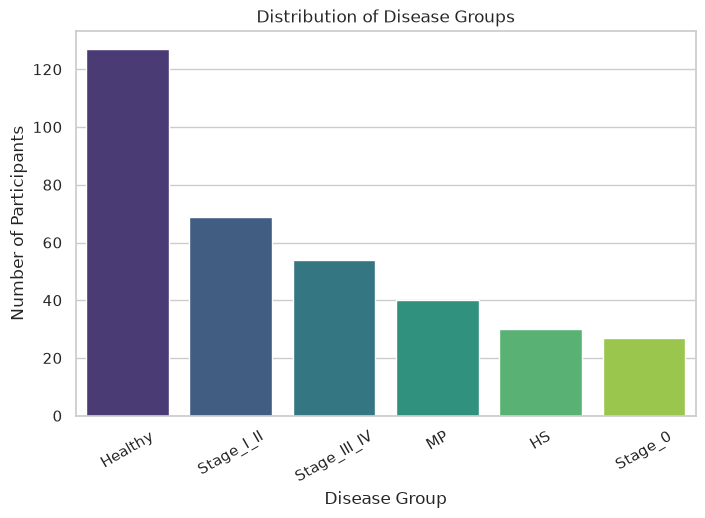

In [15]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=metadata,
    x="Study.Group",
    order=metadata["Study.Group"].value_counts().index,
    palette="viridis"
)

plt.title("Distribution of Disease Groups")
plt.xlabel("Disease Group")
plt.ylabel("Number of Participants")
plt.xticks(rotation=30)

plt.show()

**Which group is the largest? Which group is the smallest? Is the cohort balanced?**

This bar chart displays the number of participants in each disease group within the paired Yachida dataset.

Healthy is the largest group with 127 participants.
Stage I/II is the second largest (69 participants).
Stage III/IV contains 54 participants.
MP has 40 participants.
HS has 30 participants.
Stage 0 is the smallest group with 27 participants.

The cohort contains participants spanning the progression from healthy individuals to advanced colorectal cancer, allowing comparisons across different stages of disease development.

However, the distribution of participants is not balanced. Healthy individuals are substantially more numerous than the early disease groups.

This imbalance means that if we later train a classifier, it could become biased toward predicting the Healthy class simply because it has many more examples.

To reduce this risk we should use:

Stratified train-test splitting
Stratified cross-validation
Appropriate evaluation metrics (e.g., ROC-AUC, balanced accuracy, F1-score depending on the task)

### Age

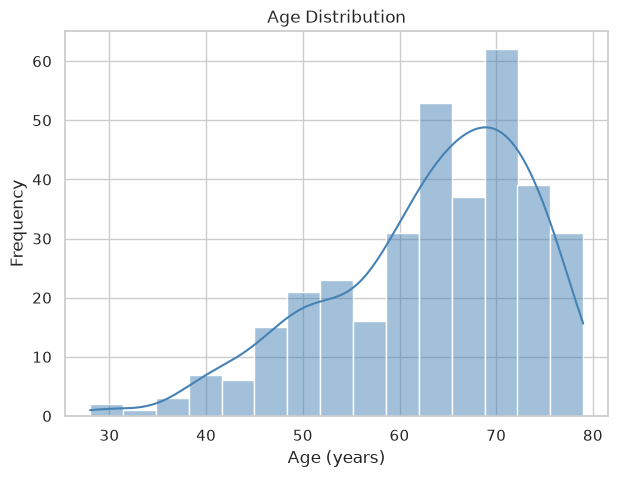

In [16]:
plt.figure(figsize=(7,5))

sns.histplot(
    metadata["Age"],
    bins=15,
    kde=True,
    color="steelblue"
)

plt.title("Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Frequency")

plt.show()

Is the distribution approximately symmetric?
Are there very young or very old outliers?

The histogram displays the distribution of participants' ages in the study cohort.

Most participants are between 60 and 75 years.
Very few participants are younger than 40 years.
The age range spans approximately 28 to 79 years.
The distribution is slightly left-skewed (negatively skewed) because there are relatively few younger participants and most observations are concentrated at older ages.

This age distribution is expected because colorectal cancer is predominantly a disease of older adults. The cohort therefore mainly consists of middle-aged and elderly individuals.

/tmp/ipykernel_1012100/2807496436.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


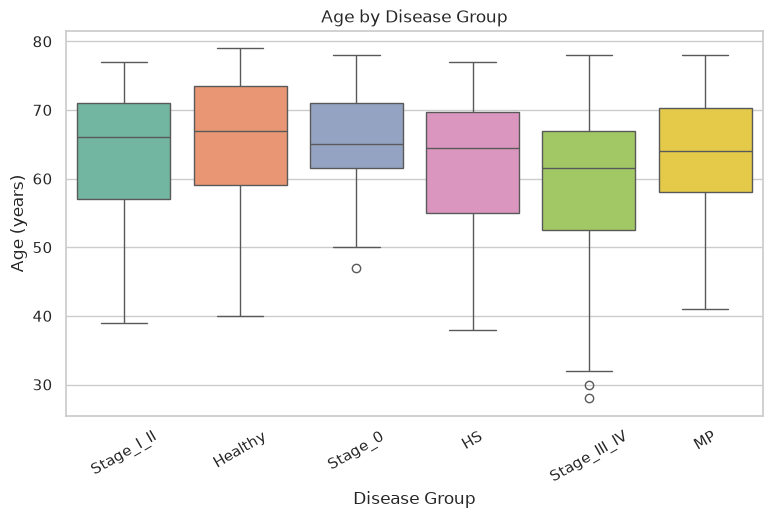

In [17]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=metadata,
    x="Study.Group",
    y="Age",
    palette="Set2"
)

plt.title("Age by Disease Group")
plt.xlabel("Disease Group")
plt.ylabel("Age (years)")
plt.xticks(rotation=30)

plt.show()

**Which group has the highest median age?**
**Are there obvious outliers?**
**Do the groups overlap?**

The boxplot compares age across the six disease groups.

The median age is similar across all disease groups (roughly in the low-to-mid 60s).
The interquartile ranges (IQRs) overlap considerably, indicating similar age distributions.
Stage III/IV shows a few younger outliers (around 28–30 years).
The Healthy group appears to have a slightly higher median age than some disease groups, but the differences are modest.

Based on the boxplot alone, there is no obvious visual evidence that one disease group is substantially older or younger than the others. We'll formally test this with the Kruskal–Wallis test, since age is not guaranteed to follow a normal distribution.

**Why Kruskal-Wallis test?**

We are comparing:

One continuous variable: Age
Across more than two independent groups: Healthy, HS, MP, Stage 0, Stage I/II, Stage III/IV

Age may not be normally distributed within every group, and some groups have relatively small sample sizes (e.g., Stage 0 has 27 participants). The Kruskal–Wallis test is a non-parametric alternative to one-way ANOVA that compares the distributions (or, more precisely, the ranks) across multiple independent groups without assuming normality.

### BMI

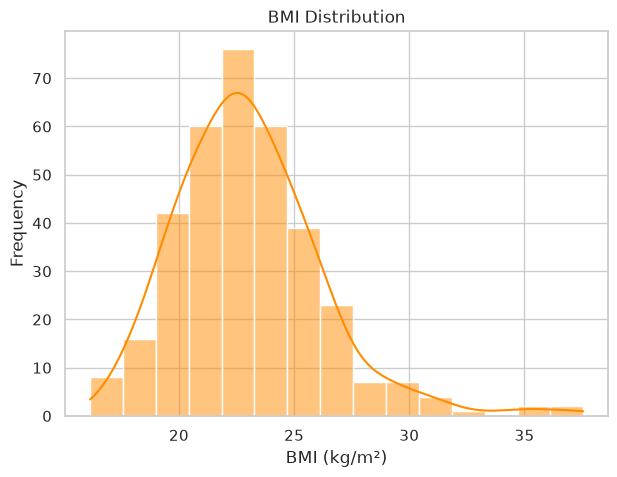

In [18]:
plt.figure(figsize=(7,5))

sns.histplot(
    metadata["BMI"],
    bins=15,
    kde=True,
    color="darkorange"
)

plt.title("BMI Distribution")
plt.xlabel("BMI (kg/m²)")
plt.ylabel("Frequency")

plt.show()

The histogram illustrates the distribution of body mass index (BMI) among the study participants.



Most BMI values lie between 20 and 26 kg/m².
The distribution is slightly right-skewed (positively skewed), with a small number of participants having higher BMI values (>30 kg/m²).
There are no obvious gaps or multiple peaks, suggesting a single main distribution.

The majority of participants fall within the normal to overweight BMI range. A few individuals with higher BMI values are present, but these appear to be isolated rather than forming a distinct subgroup.

/tmp/ipykernel_1012100/2608583662.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


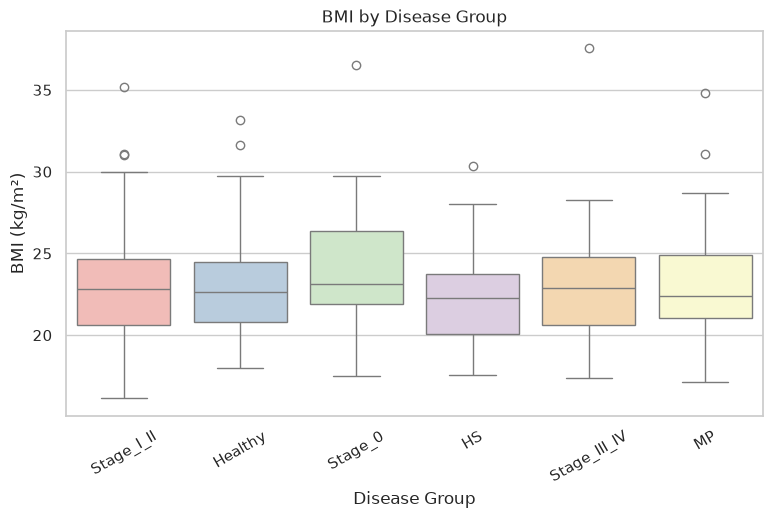

In [19]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=metadata,
    x="Study.Group",
    y="BMI",
    palette="Pastel1"
)

plt.title("BMI by Disease Group")
plt.xlabel("Disease Group")
plt.ylabel("BMI (kg/m²)")
plt.xticks(rotation=30)

plt.show()

Do BMI values overlap across groups?
Any high-BMI outliers?

The boxplot compares BMI across the six disease groups.


Median BMI values are very similar across all disease groups.
The interquartile ranges overlap substantially.
Several groups contain high-BMI outliers (approximately 30–38 kg/m²).
No disease group appears to have consistently higher or lower BMI than the others based on visual inspection.

There is no obvious visual evidence that BMI differs systematically between disease groups. The overlapping distributions suggest that BMI is unlikely to vary greatly across the cohort, although this should be formally assessed using the **Kruskal–Wallis test**.

### Gender

/tmp/ipykernel_1012100/50826002.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


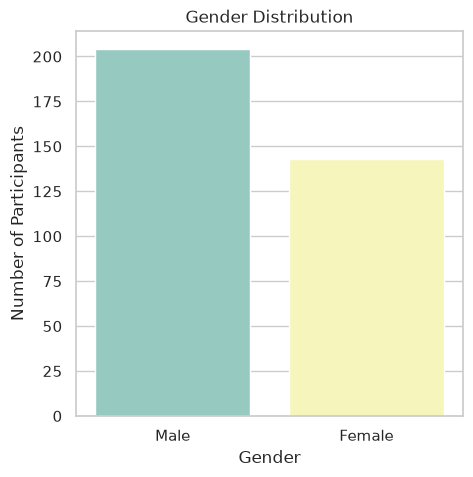

In [20]:
plt.figure(figsize=(5,5))

sns.countplot(
    data=metadata,
    x="Gender",
    palette="Set3"
)

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Participants")

plt.show()

The study cohort has a moderate male predominance. This is not unexpected, as colorectal cancer incidence is generally higher in males than females. However, whether sex differs significantly across disease groups should be assessed statistically rather than assumed from the overall counts.

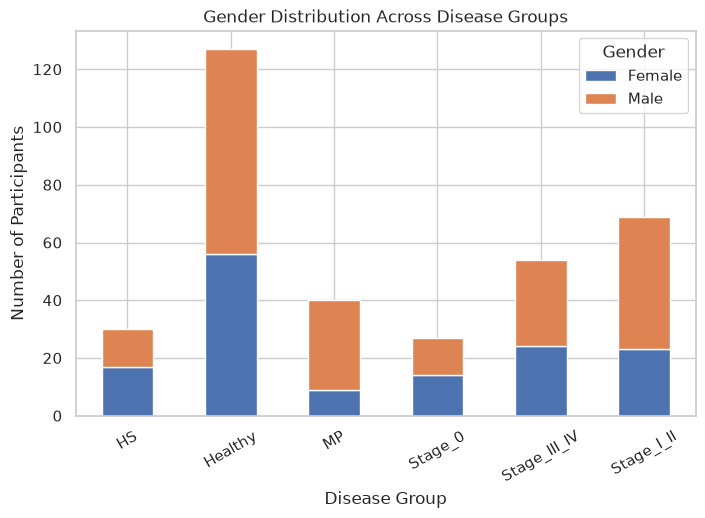

In [21]:
gender_table = pd.crosstab(
    metadata["Study.Group"],
    metadata["Gender"]
)

gender_table.plot(
    kind="bar",
    stacked=True,
    figsize=(8,5)
)

plt.title("Gender Distribution Across Disease Groups")
plt.xlabel("Disease Group")
plt.ylabel("Number of Participants")
plt.xticks(rotation=30)

plt.show()

The stacked bar chart compares the number of male and female participants within each disease group.


Every disease group contains both males and females.
Healthy, Stage I/II, and MP appear to have more males than females.
HS and Stage 0 appear relatively balanced.
The differences are visual observations only and require formal statistical testing.

**Why do we use the Chi-square test here?**

Think about the type of data:

Variable	Type
Gender	Categorical
Study.Group	Categorical

We're not comparing means or medians. Instead, we want to know whether **the distribution of one categorical variable depends on another**.

The **Chi-square test of independence** asks:

Is gender associated with disease group, or are they independent?

If the p-value is:

< 0.05: there is evidence of an association between gender and disease group.

≥ 0.05: there is no statistically significant evidence of an association.

### Smoking (Brinkman Index)

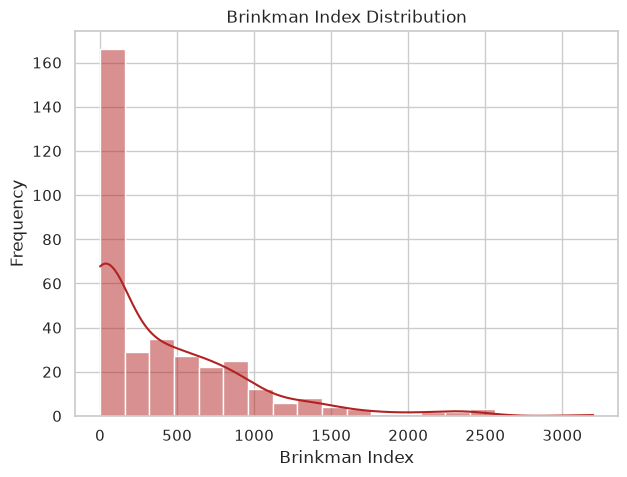

In [22]:
plt.figure(figsize=(7,5))

sns.histplot(
    metadata["Brinkman Index"],
    bins=20,
    kde=True,
    color="firebrick"
)

plt.title("Brinkman Index Distribution")
plt.xlabel("Brinkman Index")
plt.ylabel("Frequency")

plt.show()

The histogram displays the distribution of the Brinkman Index, a measure of lifetime smoking exposure calculated as:

Number of cigarettes smoked per day × years of smoking

There is a very large peak at 0, indicating that many participants are non-smokers.
The distribution is strongly right-skewed, with a long tail extending to values above 3000.
A small number of participants have extremely high smoking exposure.

The cohort contains many non-smokers alongside a smaller number of heavy smokers. The presence of extreme values suggests considerable variability in smoking history, making the distribution highly non-normal.

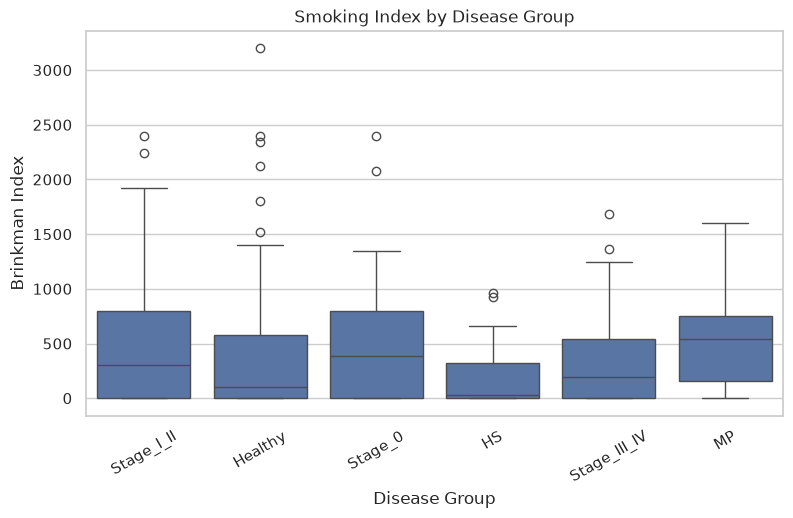

In [23]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=metadata,
    x="Study.Group",
    y="Brinkman Index"
)

plt.title("Smoking Index by Disease Group")
plt.xlabel("Disease Group")
plt.ylabel("Brinkman Index")
plt.xticks(rotation=30)

plt.show()

The boxplot compares smoking exposure among the disease groups.

From the figure:

Median Brinkman Index values vary between disease groups.
There is substantial overlap in the interquartile ranges.
Every disease group contains several high-value outliers.
MP appears to have a somewhat higher median smoking exposure than some other groups, but there is also large within-group variability.

Although some differences in smoking exposure are visible between groups, the large overlap and high variability make it difficult to conclude that smoking differs systematically across disease stages based on visual inspection alone.

**Why this matters for your project**

Smoking is a potential confounder.

A confounder is a variable that may influence both:

the gut microbiome and metabolome, and
the risk of colorectal cancer.

If smoking differs substantially between disease groups, some microbial or metabolic differences could reflect smoking habits rather than disease itself. Identifying such variables early is an important part of exploratory analysis.

**Would you use a t-test to compare Brinkman Index between groups?**

No.

Why?

Because the distribution is:

highly skewed,
contains many zeros,
has extreme outliers.

These characteristics violate the assumptions of many parametric tests. That's why we have been choosing non-parametric methods (such as the Kruskal–Wallis test) for continuous variables when appropriate.

### Alcohol Consumption

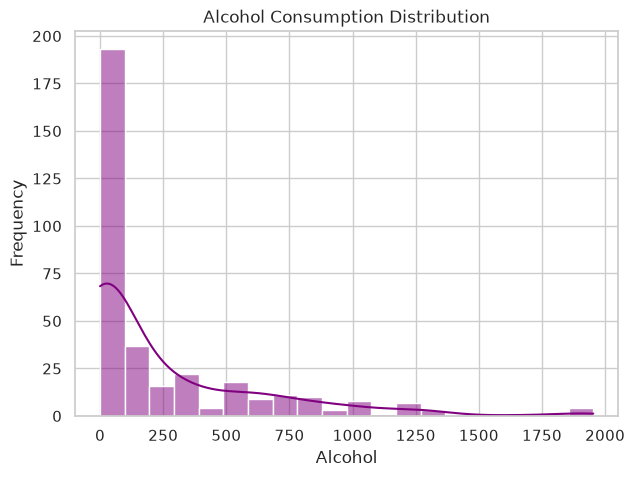

In [24]:
plt.figure(figsize=(7,5))

sns.histplot(
    metadata["Alcohol"],
    bins=20,
    kde=True,
    color="purple"
)

plt.title("Alcohol Consumption Distribution")
plt.xlabel("Alcohol")
plt.ylabel("Frequency")

plt.show()

The histogram illustrates the distribution of alcohol consumption among the study participants.

From the figure:

There is a pronounced peak at 0, indicating that many participants reported no alcohol consumption.
The distribution is strongly right-skewed, with a long tail extending to approximately 1950.
A relatively small number of participants reported very high alcohol consumption.

Most participants reported little or no alcohol intake, while a small proportion had substantially higher alcohol consumption. This results in a highly non-normal distribution with several extreme values

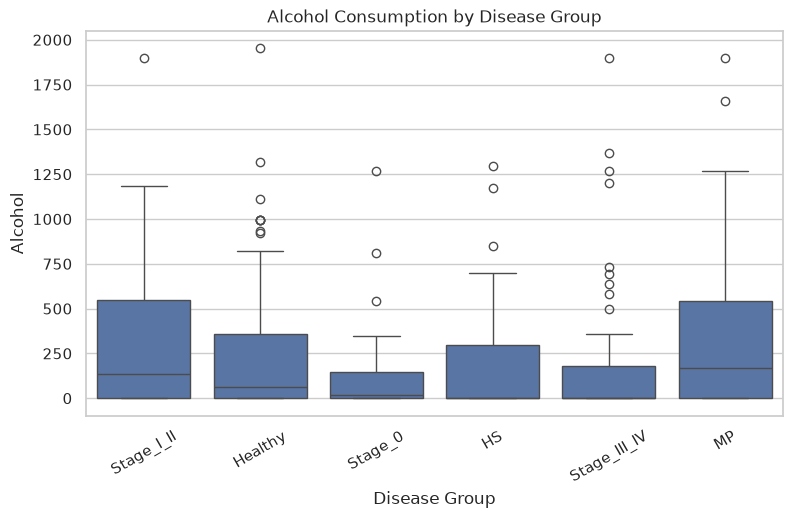

In [25]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=metadata,
    x="Study.Group",
    y="Alcohol"
)

plt.title("Alcohol Consumption by Disease Group")
plt.xlabel("Disease Group")
plt.ylabel("Alcohol")
plt.xticks(rotation=30)

plt.show()

The boxplot compares alcohol consumption across the six disease groups.

Median alcohol consumption varies slightly between disease groups.
MP and Stage I/II appear to have somewhat higher median alcohol consumption than some of the other groups.
All groups exhibit wide variability and several high-value outliers.
The interquartile ranges overlap considerably.

Although some variation in alcohol consumption is visible between disease groups, there is substantial within-group variability and overlapping distributions. Visual inspection alone is therefore insufficient to conclude that alcohol consumption differs between disease groups.

| Variable       | Plot                     | Why?                                          |
| -------------- | ------------------------ | --------------------------------------------- |
| Disease group  | Count plot               | Check class balance                           |
| Age            | Histogram + Boxplot      | Distribution and group differences            |
| BMI            | Histogram + Boxplot      | Distribution and potential confounding        |
| Gender         | Count plot + Stacked bar | Sex balance overall and within groups         |
| Brinkman Index | Histogram + Boxplot      | Smoking distribution and skewness             |
| Alcohol        | Histogram + Boxplot      | Alcohol consumption distribution and skewness |


| Variable       | Observation                                                                    |
| -------------- | ------------------------------------------------------------------------------ |
| Disease Group  | Moderately imbalanced (Healthy largest, Stage 0 smallest)                      |
| Age            | Mostly 60–75 years, similar across groups with a few younger outliers          |
| BMI            | Similar across groups, slight positive skew with some high-BMI outliers        |
| Gender         | More males than females overall; both sexes represented in every disease group |
| Brinkman Index | Strongly right-skewed, many non-smokers, several heavy-smoking outliers        |
| Alcohol        | Strongly right-skewed, many non-drinkers, several high-consumption outliers    |


One thing to notice is that Brinkman Index and Alcohol are potential confounders because they are known risk factors for colorectal cancer and can also influence the gut microbiome and metabolome. In this project, we're describing these variables to characterize the cohort and identify potential sources of variation. Whether they need to be included as covariates in later analyses depends on the specific statistical model and research question.

Statistical Testing

| Variable | Test            | Why?                                                                     |
| -------- | --------------- | ------------------------------------------------------------------------ |
| Age      | Kruskal–Wallis  | Continuous variable, six independent groups, no need to assume normality |
| BMI      | Kruskal–Wallis  | Continuous variable, six independent groups, no need to assume normality |
| Gender   | Chi-square test | Both variables are categorical                                           |


**Why did use Kruskal–Wallis instead of ANOVA?**

Although the overall age distribution appeared approximately symmetric, the comparison involves six independent disease groups with unequal sample sizes, and normality within each group was not assumed. Therefore, the non-parametric Kruskal–Wallis test was selected because it does not require normally distributed data and is more robust to outliers.

The Kruskal–Wallis test compares the **ranks** of observations rather than their actual values, making it less sensitive to non-normal distributions and outliers. For example, a set of ages such as **28, 45, 57, 61, 65, 70, and 78 years** would first be converted into their ranks (**1, 2, 3, 4, 5, 6, and 7**) before comparing the distributions across disease groups. Because the analysis is based on ranks rather than raw measurements, the Kruskal–Wallis test provides a robust alternative to one-way ANOVA when normality cannot be assumed, which is often the case in biomedical datasets with unequal group sizes and outliers.


## Kruskal–Wallis Test: Age

**Null hypothesis (H₀):**
The age distributions are the same across all disease groups.

**Alternative hypothesis (H₁):**
At least one disease group has a different age distribution.

In [26]:
from scipy.stats import kruskal

age_groups = [
    metadata.loc[metadata["Study.Group"] == "Healthy", "Age"],
    metadata.loc[metadata["Study.Group"] == "HS", "Age"],
    metadata.loc[metadata["Study.Group"] == "MP", "Age"],
    metadata.loc[metadata["Study.Group"] == "Stage_0", "Age"],
    metadata.loc[metadata["Study.Group"] == "Stage_I_II", "Age"],
    metadata.loc[metadata["Study.Group"] == "Stage_III_IV", "Age"]
]

statistic, p_value = kruskal(*age_groups)

print(f"Kruskal-Wallis statistic for age: {statistic:.3f}")
print(f"P-value: {p_value:.4f}")

Kruskal-Wallis statistic for age: 12.193
P-value: 0.0322


A Kruskal–Wallis test revealed a statistically significant difference in age among the six disease groups (H = 12.19, p = 0.032). This suggests that the age distribution differs across at least one disease stage.

Age is not evenly distributed across the disease groups.

This isn't surprising because colorectal cancer incidence generally increases with age. It also means age could act as a confounding variable in later machine learning analyses. When we build predictive models, we'll want to discuss that differences in microbiome composition could partly reflect age differences rather than disease status alone.

## Kruskal–Wallis Test: BMI

**H₀:** BMI distributions are the same across disease groups.

**H₁:** At least one disease group has a different BMI distribution.

In [27]:
bmi_groups = [
    metadata.loc[metadata["Study.Group"] == "Healthy", "BMI"],
    metadata.loc[metadata["Study.Group"] == "HS", "BMI"],
    metadata.loc[metadata["Study.Group"] == "MP", "BMI"],
    metadata.loc[metadata["Study.Group"] == "Stage_0", "BMI"],
    metadata.loc[metadata["Study.Group"] == "Stage_I_II", "BMI"],
    metadata.loc[metadata["Study.Group"] == "Stage_III_IV", "BMI"]
]

statistic, p_value = kruskal(*bmi_groups)

print(f"Kruskal-Wallis statistic for BMI: {statistic:.3f}")
print(f"P-value: {p_value:.4f}")

Kruskal-Wallis statistic for BMI: 3.567
P-value: 0.6133


No statistically significant differences in BMI were observed among the disease groups (H = 3.57, p = 0.613).

BMI appears relatively similar across all study groups.

This suggests BMI is less likely to be a major confounder in the dataset compared with age.

## Chi-square Test: Gender

**H₀:** Gender and disease group are independent.

**H₁:** Gender distribution differs between disease groups.

In [28]:
from scipy.stats import chi2_contingency

gender_table = pd.crosstab(
    metadata["Study.Group"],
    metadata["Gender"]
)

chi2, p_value, dof, expected = chi2_contingency(gender_table)

print(f"Chi-square statistic for gender: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.4f}")

Chi-square statistic for gender: 12.436
Degrees of freedom: 5
P-value: 0.0293


A Chi-square test showed a significant association between gender and disease group (χ² = 12.44, df = 5, p = 0.029).

The proportion of males and females differs significantly across the disease groups.

Like age, this means sex may also be a confounding factor when interpreting downstream microbiome and metabolomic differences.

# **Phase 2 — Metagenomics Analysis**

# Dataset Overview

In [33]:
species = pd.read_csv("data/species.tsv.zip", sep="\t")

# Verify sample order matches metadata before doing anything else
assert (species["Sample"].values == metadata["Sample"].values).all(), \
    "Sample order mismatch: species vs metadata — do not proceed until fixed"

AssertionError: Sample order mismatch: species vs metadata — do not proceed until fixed

In [36]:
meta_samples = set(metadata["Sample"])
species_samples = set(species["Sample"])
print("Same set of samples:", meta_samples == species_samples)
print("In metadata but not species:", meta_samples - species_samples)
print("In species but not metadata:", species_samples - meta_samples)
print("metadata shape:", metadata.shape[0], "| species shape:", species.shape[0])

Same set of samples: True
In metadata but not species: set()
In species but not metadata: set()
metadata shape: 347 | species shape: 347


In [37]:
species = species.set_index("Sample").loc[metadata["Sample"]].reset_index()
assert (species["Sample"].values == metadata["Sample"].values).all(), \
    "Still mismatched after reorder"

/tmp/ipykernel_1012100/3498871831.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  species = species.set_index("Sample").loc[metadata["Sample"]].reset_index()


In [39]:
print("Shape:", species.shape)

Shape: (347, 57703)


In [40]:
species.head()

,Sample,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965,d__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795,d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibacteraceae;g__JAAYPI01;s__JAAYPI01 sp012519885,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Flavobacteriaceae;g__Flavobacterium;s__Flavobacterium sp017989775,...,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1;s__LC3-1 sp016781735,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Sphingomonadales;f__Sphingomonadaceae;g__Sphingorhabdus_B;s__Sphingorhabdus_B sp012032285,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Pseudomonadaceae;g__Pseudomonas_E;s__Pseudomonas_E sp900187445,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902591535,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales_A;f__Enterobacteriaceae_A;g__GCA-012562765;s__GCA-012562765 sp012569925,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902631135,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Puniceispirillales;f__Puniceispirillaceae;g__UBA5951;s__UBA5951 sp902625725,d__Bacteria;p__Verrucomicrobiota;c__Kiritimatiellae;o__SS1-B-03-39;f__UBA6053;g__PXAS01;s__PXAS01 sp003565815,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451;s__UBA7451 sp002457275,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__CACIJG01;s__CACIJG01 sp902580265
0,10021,0.000181,0.0,0.0,0.000006,0.0,0.000002,1.301684e-06,3.154081e-06,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
1,10023,0.000499,0.0,0.0,0.000008,0.0,0.000002,2.213688e-06,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
2,10025,0.000018,0.0,0.0,0.000005,0.0,0.000002,2.976180e-07,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
3,10029,0.000051,0.0,0.0,0.000003,0.0,0.000005,4.691933e-07,2.580563e-07,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0
4,10031,0.000011,0.0,0.0,0.000000,0.0,0.000002,5.167816e-07,0.000000e+00,0.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0


In [41]:
species.columns

Index(['Sample',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965',
       'd__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795',
       'd__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibactera

In [42]:
species.info()

<class 'pandas.DataFrame'>
RangeIndex: 347 entries, 0 to 346
Columns: 57703 entries, Sample to d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__CACIJG01;s__CACIJG01 sp902580265
dtypes: float64(56235), int64(1468)
memory usage: 152.8 MB


In [43]:
species.describe()

,Sample,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965,d__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795,d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum,d__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845,d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibacteraceae;g__JAAYPI01;s__JAAYPI01 sp012519885,d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Flavobacteriales;f__Flavobacteriaceae;g__Flavobacterium;s__Flavobacterium sp017989775,...,d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1;s__LC3-1 sp016781735,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Sphingomonadales;f__Sphingomonadaceae;g__Sphingorhabdus_B;s__Sphingorhabdus_B sp012032285,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__Pseudomonadaceae;g__Pseudomonas_E;s__Pseudomonas_E sp900187445,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902591535,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Enterobacterales_A;f__Enterobacteriaceae_A;g__GCA-012562765;s__GCA-012562765 sp012569925,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter;s__Pelagibacter sp902631135,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Puniceispirillales;f__Puniceispirillaceae;g__UBA5951;s__UBA5951 sp902625725,d__Bacteria;p__Verrucomicrobiota;c__Kiritimatiellae;o__SS1-B-03-39;f__UBA6053;g__PXAS01;s__PXAS01 sp003565815,d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Pseudomonadales;f__HTCC2089;g__UBA7451;s__UBA7451 sp002457275,d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__CACIJG01;s__CACIJG01 sp902580265
count,347.000000,347.000000,3.470000e+02,3.470000e+02,347.000000,3.470000e+02,347.000000,3.470000e+02,3.470000e+02,3.470000e+02,...,347.0,347.0,347.0,347.0,3.470000e+02,3.470000e+02,3.470000e+02,3.470000e+02,3.470000e+02,347.0
mean,10412.737752,0.000117,3.886579e-08,3.335300e-08,0.000011,1.479526e-07,0.000005,3.573476e-06,1.136510e-06,6.255071e-08,...,0.0,0.0,0.0,0.0,7.874513e-10,8.436979e-10,1.068684e-09,3.824764e-09,7.874513e-10,0.0
std,242.378407,0.000145,1.796534e-07,3.646770e-07,0.000038,5.297408e-07,0.000005,1.008352e-05,9.561927e-06,2.866107e-07,...,0.0,0.0,0.0,0.0,1.466859e-08,1.571635e-08,1.990738e-08,7.124745e-08,1.466859e-08,0.0
min,10021.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
25%,10214.000000,0.000032,0.000000e+00,0.000000e+00,0.000001,0.000000e+00,0.000002,0.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
50%,10354.000000,0.000079,0.000000e+00,0.000000e+00,0.000003,0.000000e+00,0.000004,8.809225e-07,0.000000e+00,0.000000e+00,...,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
75%,10631.000000,0.000150,0.000000e+00,0.000000e+00,0.000008,0.000000e+00,0.000007,2.216015e-06,3.725041e-07,0.000000e+00,...,0.0,0.0,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.0
max,10853.000000,0.001117,1.880146e-06,5.220535e-06,0.000452,3.882755e-06,0.000042,7.949989e-05,1.528579e-04,3.

In [ ]:
print(species.columns[1:11])

Index(['d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae;g__Odoribacter;s__Odoribacter sp905193145',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__AKYH767;f__JACCXN01;g__JACCXN01;s__JACCXN01 sp013696965',
       'd__Bacteria;p__Desulfobacterota_G;c__Syntrophorhabdia;o__Syntrophorhabdales;f__Syntrophorhabdaceae;g__UBA8905;s__UBA8905 sp002402795',
       'd__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Mycobacteriales;f__Mycobacteriaceae;g__Corynebacterium;s__Corynebacterium durum',
       'd__Bacteria;p__Firmicutes;c__Bacilli;o__Acholeplasmatales;f__Acholeplasmataceae;g__UBA2284;s__UBA2284 sp001830045',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae;g__An92;s__An92 sp009935845',
       'd__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Acutalibacteraceae;g__Avimonas;s__Avimonas sp012522615',
       'd__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Paludibacteraceae;g__JAAYPI01;

The species-level metagenomics dataset contains 347 samples and 57,702 microbial species features. Each row represents one participant, and each microbial column represents the relative abundance of a species-level taxon. The feature names include full taxonomic lineage from domain to species level. The dataset is highly sparse and high-dimensional, which is typical for metagenomic abundance data and motivates quality control and low-abundance feature filtering before exploratory analyses such as PCA and UMAP.

# Quality Control

In [44]:
# Define species feature columns
species_cols = species.columns[1:]

print("Number of samples:", species.shape[0])
print("Number of species features:", len(species_cols))

Number of samples: 347
Number of species features: 57702


In [45]:
# Missing values
print("Total missing values:", species.isna().sum().sum())

Total missing values: 0


In [46]:
# Duplicate sample IDs
print("Duplicate Sample IDs:", species["Sample"].duplicated().sum())
print("Unique Sample IDs:", species["Sample"].nunique())

Duplicate Sample IDs: 0
Unique Sample IDs: 347


In [47]:
# Check whether values are relative abundances by looking at row sums
row_sums = species[species_cols].sum(axis=1)

row_sums.describe()

count    3.470000e+02
mean     1.000000e+00
std      2.474460e-14
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

In [48]:
# Count zeros
zero_fraction_per_species = (species[species_cols] == 0).mean()

zero_fraction_per_species.describe()

count    57702.000000
mean         0.850122
std          0.248015
min          0.000000
25%          0.855908
50%          0.962536
75%          0.988473
max          1.000000
dtype: float64

In [49]:
# Species with the most zeros
zero_fraction_per_species.sort_values(ascending=False).head(20)

d__Bacteria;p__Gemmatimonadota;c__Gemmatimonadetes;o__Longimicrobiales;f__UBA6960;g__GCA-2718595;s__GCA-2718595 sp012959595                      1.0
d__Bacteria;p__Proteobacteria;c__Gammaproteobacteria;o__Arenicellales;f__LS-SOB;g__VYGS01;s__VYGS01 sp009839585                                  1.0
d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Sphingomonadales;f__Sphingomonadaceae;g__Erythrobacter;s__Erythrobacter sp003149575      1.0
d__Bacteria;p__Actinobacteriota;c__Actinomycetia;o__Nanopelagicales;f__UBA5976;g__UBA5976;s__UBA5976 sp903925705                                 1.0
d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Pelagibacterales;f__Pelagibacteraceae;g__Pelagibacter_A;s__Pelagibacter_A sp902625945    1.0
d__Bacteria;p__Chloroflexota;c__Chloroflexia;o__Thermobaculales;f__Thermobaculaceae;g__LC3-1;s__LC3-1 sp016781735                                1.0
d__Bacteria;p__Proteobacteria;c__Alphaproteobacteria;o__Rhodobacterales;f__Rhodobacteraceae;g__MED-G52;s__

No missing values

Total missing values = 0, so no imputation is needed.

No duplicate samples

Duplicate Sample IDs = 0 and unique samples = 347, so every participant appears once.

Data are already relative abundances

The row sums are exactly ~1 for every sample. This means each sample’s microbial abundances sum to 100%, so the table is already normalized.

The data are extremely sparse

Mean zero fraction = 0.85, meaning the average species is absent in about 85% of samples. The median zero fraction is 0.96, so half of the species are absent in at least 96% of samples.

This is normal for species-level microbiome data, but it means we should filter rare taxa before PCA/UMAP.

The species-level metagenomics dataset showed no missing values or duplicate sample identifiers. Row sums were approximately equal to 1 for all samples, confirming that the data represent relative abundances. However, the dataset was highly sparse: the average species was absent in approximately 85% of samples, and the median species was absent in approximately 96% of samples. Therefore, low-prevalence taxa should be filtered before downstream dimensionality reduction to reduce noise and computational burden.

In [50]:
# Keep species present in at least 10% of samples
prevalence = (species[species_cols] > 0).mean()

keep_species = prevalence[prevalence >= 0.10].index

species_filtered = species[["Sample"] + list(keep_species)]

print("Original shape:", species.shape)
print("Filtered shape:", species_filtered.shape)
print("Number of retained species:", len(keep_species))

Original shape: (347, 57703)
Filtered shape: (347, 17693)
Number of retained species: 17692


Before filtering:

347 samples
57,702 microbial species

After filtering:

347 samples
17,692 microbial species

That means we removed:

40,010 rare species (about 69% of the original features)

while keeping all 347 participants.

This is actually a good outcome. In metagenomics, most detected species are extremely rare and contribute little to global patterns but add computational burden and noise.

**why filtering helps?**

PCA and UMAP try to identify the main sources of variation in the data. Species that appear in only a handful of samples:

* contribute very little to overall variation,
* are often dominated by sequencing noise,
* increase computational time,
* can obscure biologically meaningful patterns.

Filtering low-prevalence taxa improves the signal-to-noise ratio without discarding samples.

# Distribution Assessment

In [51]:
# Top 10 most prevalent species
prevalence.sort_values(ascending=False).head(10)

d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Anaerotignaceae;g__Anaerotignum;s__Anaerotignum lactatifermentans     1.0
d__Bacteria;p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae;g__Bacteroides;s__Bacteroides sp012113595              1.0
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Butyricicoccaceae;g__Butyricicoccus;s__Butyricicoccus sp900604335    1.0
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Oliverpabstia;s__Oliverpabstia faecicola           1.0
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Limivivens;s__Limivivens sp900543575               1.0
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Clostridium_AP;s__Clostridium_AP scindens          1.0
d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae;g__Blautia_A;s__Blautia_A schinkii                    1.0
d__Bacteria;p__Bacteroidota;c__Bacteroidi

In [52]:
# Select the most prevalent species
example_species = prevalence.sort_values(ascending=False).index[0]

print(example_species)

d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Anaerotignaceae;g__Anaerotignum;s__Anaerotignum lactatifermentans


In [53]:
species_filtered[example_species].describe()

count    3.470000e+02
mean     8.188862e-04
std      2.504409e-03
min      9.446252e-07
25%      2.117937e-05
50%      6.382209e-05
75%      2.219759e-04
max      1.792999e-02
Name: d__Bacteria;p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Anaerotignaceae;g__Anaerotignum;s__Anaerotignum lactatifermentans, dtype: float64

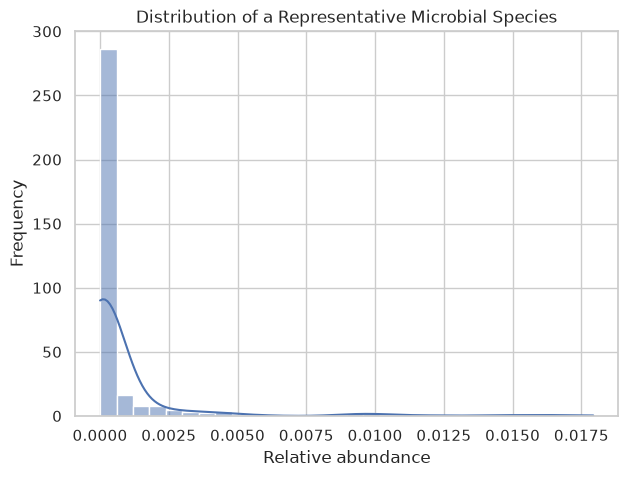

In [54]:
plt.figure(figsize=(7,5))

sns.histplot(
    species_filtered[example_species],
    bins=30,
    kde=True
)

plt.title("Distribution of a Representative Microbial Species")
plt.xlabel("Relative abundance")
plt.ylabel("Frequency")

plt.show()

Most samples have abundances very close to 0.
A small number of samples have much larger abundances.
The long right tail compresses almost all observations into the first few bins.

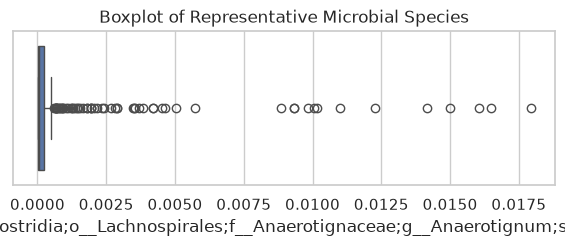

In [55]:
plt.figure(figsize=(7,2))

sns.boxplot(
    x=species_filtered[example_species]
)

plt.title("Boxplot of Representative Microbial Species")

plt.show()

The IQR is tiny.
Almost every non-zero value is flagged as an "outlier".
Those are not necessarily biological outliers; they're a consequence of the skewed distribution.

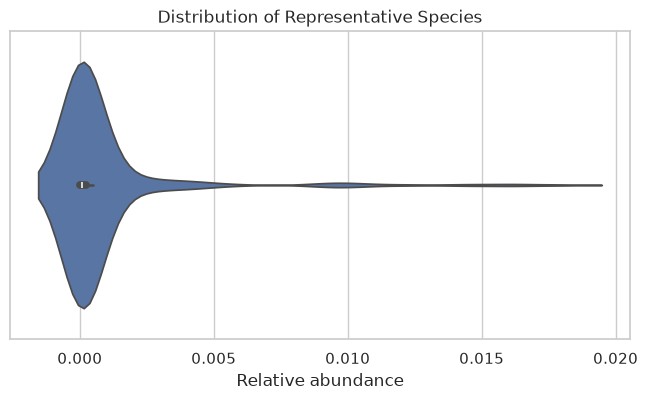

In [56]:
#violin plot
plt.figure(figsize=(8,4))

sns.violinplot(x=species_filtered[example_species])

plt.title("Distribution of Representative Species")
plt.xlabel("Relative abundance")

plt.show()

This plot confirms that the abundance of the representative species is highly concentrated near zero, with only a few samples showing higher relative abundances. The long, thin tail indicates a small number of individuals harbor substantially greater abundances of this species. This pattern is characteristic of gut microbiome data, where many taxa are present at very low abundances across most individuals.
**Conclusion:** The distribution is strongly right-skewed and not normally distributed.

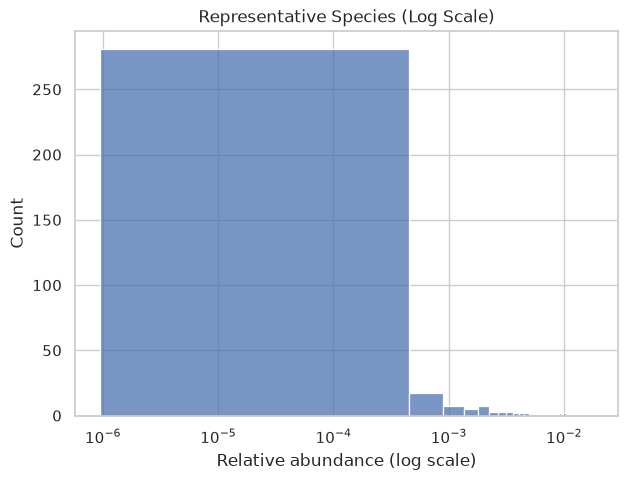

In [57]:
#histogram on a log scale
plt.figure(figsize=(7,5))

sns.histplot(
    species_filtered[example_species],
    bins=40
)

plt.xscale("log")

plt.title("Representative Species (Log Scale)")
plt.xlabel("Relative abundance (log scale)")

plt.show()

Most observations are between approximately 10
−6
 and 10
−4
.
Only a small proportion of samples contain relatively high abundances.
The abundance spans several orders of magnitude.

This wide dynamic range is typical of metagenomic relative abundance data and suggests that a log transformation (log1p) will compress extreme values and reduce skewness before dimensionality reduction.

**Conclusion:** The distribution supports applying a log transformation prior to PCA and UMAP.

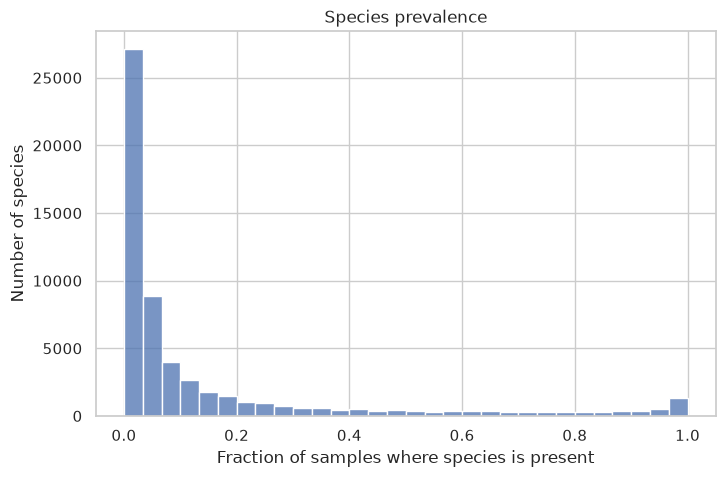

In [58]:
#Species prevalence
plt.figure(figsize=(8,5))

sns.histplot(prevalence, bins=30)

plt.xlabel("Fraction of samples where species is present")
plt.ylabel("Number of species")
plt.title("Species prevalence")

plt.show()

Most species are detected in only a small fraction of participants.
Only a relatively small number of species are present in nearly every sample.
The distribution is heavily left-skewed, demonstrating substantial sparsity.

This also validates the filtering step performed.

**Conclusion:** The dataset contains many rare taxa, making prevalence filtering an essential preprocessing step before downstream analyses.

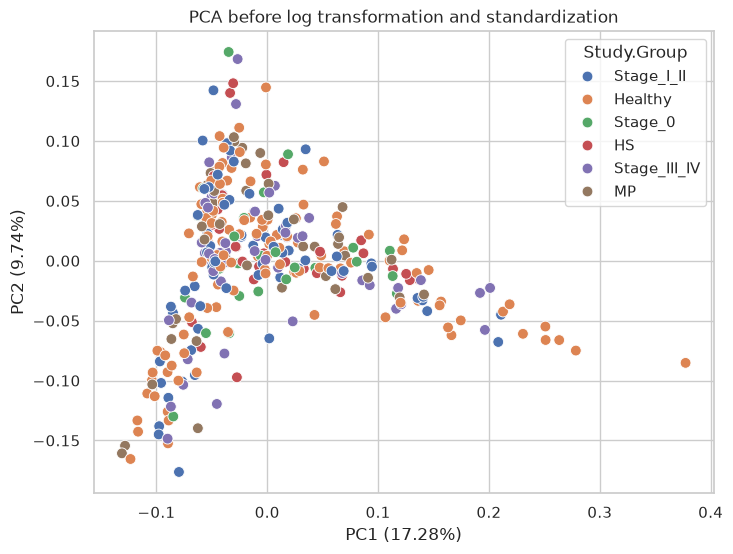

In [59]:
from sklearn.decomposition import PCA

# Raw filtered abundances (no log, no scaling)
X_raw = species_filtered[keep_species]

pca_raw = PCA(n_components=2, random_state=42)
pca_raw_result = pca_raw.fit_transform(X_raw)

pca_raw_df = pd.DataFrame(
    pca_raw_result,
    columns=["PC1", "PC2"]
)

pca_raw_df["Study.Group"] = metadata["Study.Group"]

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_raw_df,
    x="PC1",
    y="PC2",
    hue="Study.Group",
    s=60
)

plt.xlabel(f"PC1 ({pca_raw.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca_raw.explained_variance_ratio_[1]*100:.2f}%)")
plt.title("PCA before log transformation and standardization")

plt.show()

PCA before log transformation and standardization

PC1 = 17.28%
PC2 = 9.74%
Total ≈ 27.0%

# Preprocessing

### Log transformation

In [60]:
# Copy the filtered dataset
species_log = species_filtered.copy()

# Apply log1p to microbial abundance columns only
species_log[keep_species] = np.log1p(species_log[keep_species])

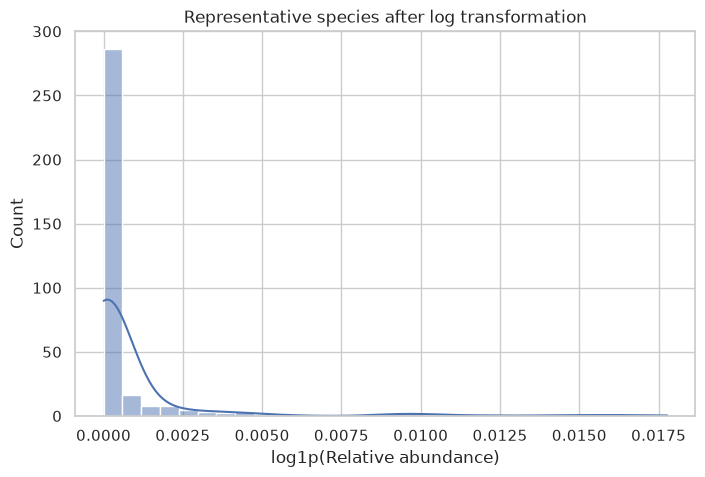

In [61]:
sns.histplot(
    species_log[example_species],
    bins=30,
    kde=True
)

plt.title("Representative species after log transformation")
plt.xlabel("log1p(Relative abundance)")
plt.show()

### Standardisation

In [62]:
from sklearn.preprocessing import StandardScaler

X = species_log[keep_species]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(347, 17692)


In [63]:
print(X_scaled.mean())
print(X_scaled.std())

-5.138859789727077e-19
1.0


In [65]:
print(round(X_scaled.mean(), 10))
print(round(X_scaled.std(), 10))

-0.0
1.0


Following log transformation, the microbial abundance data were standardized using StandardScaler. The transformed dataset had an overall mean of approximately 0 and a standard deviation of approximately 1, confirming successful standardization. This preprocessing step ensures that each microbial species contributes equally to distance calculations and variance estimation during dimensionality reduction.

# PCA

In [66]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

pca_result = pca.fit_transform(X_scaled)

print(pca_result.shape)
print(pca.explained_variance_ratio_)

(347, 2)
[0.05846195 0.02561217]


In [67]:
pca_df = pd.DataFrame(
    pca_result,
    columns=["PC1", "PC2"]
)

pca_df["Study.Group"] = metadata["Study.Group"]

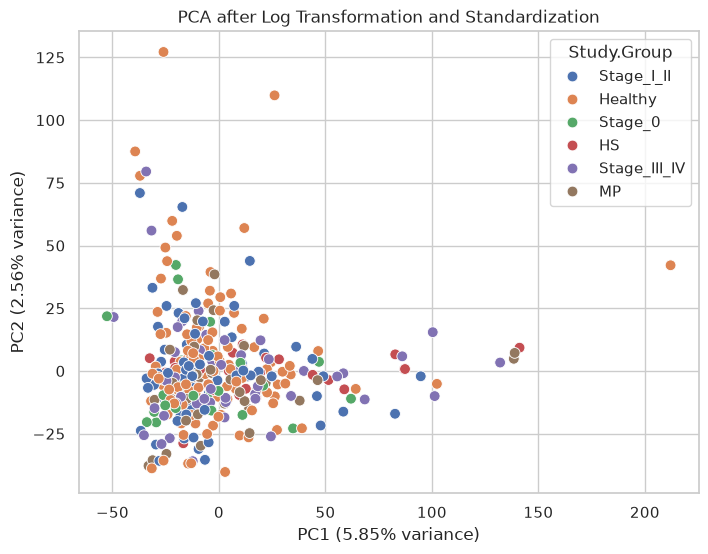

In [69]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Study.Group",
    s=60
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% variance)")
plt.title("PCA after Log Transformation and Standardization")

plt.show()

In [70]:
print(pca.explained_variance_ratio_)

[0.05846195 0.02561217]


PCA of filtered metagenomics data"

PC1 = 5.85%
PC2 = 2.56%
Total ≈ 8.41%

In [71]:
pca_df.sort_values("PC1", ascending=False).head(10)

,PC1,PC2,Study.Group
110,212.066167,42.133686,Healthy
44,141.151730,9.291500,HS
330,138.856846,7.197777,MP
62,138.450058,4.858227,MP
266,132.029016,3.359941,Stage_III_IV
336,102.342648,-5.130114,Healthy
310,101.292308,-10.006597,Stage_III_IV
66,100.390492,15.463888,Stage_III_IV
145,94.753883,-2.116522,Stage_I_II
180,87.363328,0.777776,HS


In [72]:
pca_df.sort_values("PC2", ascending=False).head(10)

,PC1,PC2,Study.Group
220,-26.038824,127.161743,Healthy
163,26.105318,109.865052,Healthy
239,-39.340775,87.517793,Healthy
64,-34.174364,79.515780,Stage_III_IV
50,-37.058235,77.803403,Healthy
155,-37.121839,70.942456,Stage_I_II
282,-17.186424,65.374775,Stage_I_II
272,-21.952245,59.837541,Healthy
326,11.895381,56.982670,Healthy
270,-31.678891,55.964322,Stage_III_IV


Before preprocessing, the first two principal components explained approximately 27.0% of the variance, indicating that a small number of highly abundant microbial species dominated the dataset. After prevalence filtering, log transformation, and standardization, the explained variance decreased to 8.41% (PC1 = 5.85%, PC2 = 2.56%). This reduction is expected for high-dimensional metagenomic data because preprocessing reduces the influence of dominant taxa and distributes variation more evenly across thousands of microbial species. Despite the lower explained variance, the processed PCA provides a more reliable representation of overall microbiome structure for downstream analyses.

# UMAP

In [75]:
%pip install umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [umap-learn]2 [umap-learn]
Note: you may need to restart the kernel to use updated packages.


In [76]:
import umap as umap

umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

umap_result = umap_model.fit_transform(X_scaled)

print(umap_result.shape)

/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(347, 2)


In [77]:
umap_df = pd.DataFrame(
    umap_result,
    columns=["UMAP1", "UMAP2"]
)

umap_df["Study.Group"] = metadata["Study.Group"]

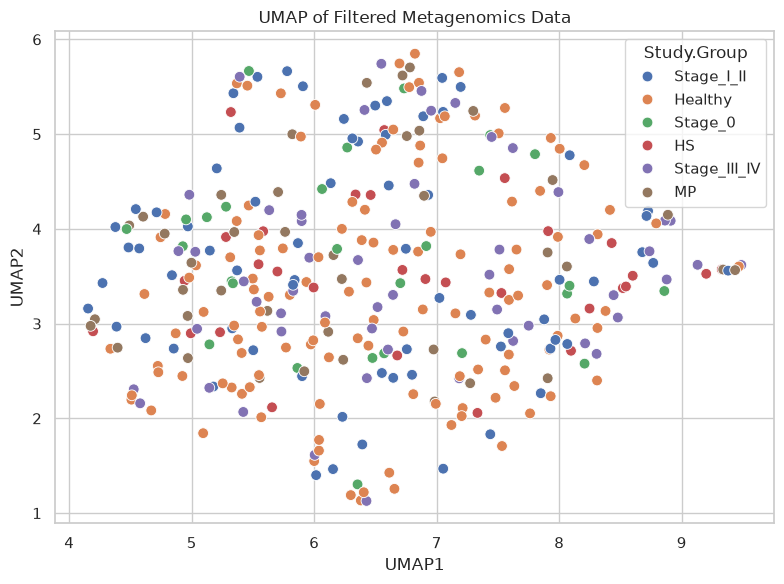

In [78]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Study.Group",
    s=60
)

plt.title("UMAP of Filtered Metagenomics Data")
plt.tight_layout()
plt.show()

UMAP of the filtered, log-transformed, and standardized metagenomics data did not show clear disease-stage separation. Samples from all disease groups were broadly mixed, suggesting that the strongest non-linear patterns in the microbiome are not driven solely by disease stage.

In [79]:
umap_df["Distance"] = np.sqrt(
    umap_df["UMAP1"]**2 +
    umap_df["UMAP2"]**2
)

umap_df.sort_values("Distance", ascending=False).head(10)

,UMAP1,UMAP2,Study.Group,Distance
66,9.486453,3.618844,Stage_III_IV,10.153267
110,9.465705,3.602732,Healthy,10.128141
330,9.435505,3.564659,MP,10.086404
318,9.378758,3.559072,Stage_I_II,10.031356
62,9.338496,3.570554,MP,9.997818
44,9.326730,3.572049,HS,9.987363
29,9.199879,3.525695,HS,9.852324
310,9.129267,3.620682,Stage_III_IV,9.821041
338,8.886986,4.148911,MP,9.807751
132,8.909596,4.085577,Stage_III_IV,9.801676


The disease groups are highly overlapping. There is no clear separate cluster for Healthy, Stage 0, Stage I/II, or Stage III/IV.

In [80]:
metadata.loc[umap_df.sort_values("Distance", ascending=False).head(10).index]

,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
66,YACHIDA_CRC_2019,10171,10171,Stage_III_IV,30,Years,Male,25.689562,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IVB,0,104.9790,Left colon,False
110,YACHIDA_CRC_2019,10254,10254,Healthy,67,Years,Female,19.675167,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,22.9267,-,False
330,YACHIDA_CRC_2019,10809,10809,MP,66,Years,Female,20.239501,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.0000,-,False
318,YACHIDA_CRC_2019,10767,10767,Stage_I_II,72,Years,Male,24.690405,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IIA,980,406.5000,Left colon,False
62,YACHIDA_CRC_2019,10161,10161,MP,51,Years,Male,21.798202,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,570,0.0000,-,False
44,YACHIDA_CRC_2019,10115,10115,HS,40,Years,Female,20.028842,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,98,0.0000,-,False
29,YACHIDA_CRC_2019,10084,10084,HS,70,Years,Female,20.703125,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,140,847.9000,-,False
310,YACHIDA_CRC_2019,10754,10754,Stage_III_IV,46,Years,Female,17.444927,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IIIB,56,1366.0000,Rectum,False
338,YACHIDA_CRC_2019,10825,10825,MP,74,Years,Male,23.051755,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,520,42.4286,-,False
132,YACHIDA_CRC_2019,10284,10284,Stage_III_IV,73,Years,Male,23.335466,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IVA,820,638.7860,Rectum,False


In [81]:
umap_df["Distance_from_center"] = np.sqrt(
    (umap_df["UMAP1"] - umap_df["UMAP1"].mean())**2 +
    (umap_df["UMAP2"] - umap_df["UMAP2"].mean())**2
)

umap_df.sort_values("Distance_from_center", ascending=False).head(10)

,UMAP1,UMAP2,Study.Group,Distance,Distance_from_center
66,9.486453,3.618844,Stage_III_IV,10.153267,2.978445
110,9.465705,3.602732,Healthy,10.128141,2.957314
330,9.435505,3.564659,MP,10.086404,2.926541
318,9.378758,3.559072,Stage_I_II,10.031356,2.869753
62,9.338496,3.570554,MP,9.997818,2.829596
44,9.326730,3.572049,HS,9.987363,2.817847
29,9.199879,3.525695,HS,9.852324,2.690838
310,9.129267,3.620682,Stage_III_IV,9.821041,2.621460
132,8.909596,4.085577,Stage_III_IV,9.801676,2.461925
338,8.886986,4.148911,MP,9.807751,2.454844


In [82]:
outlier_indices = umap_df.sort_values("Distance_from_center", ascending=False).head(10).index
metadata.loc[outlier_indices]

,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
66,YACHIDA_CRC_2019,10171,10171,Stage_III_IV,30,Years,Male,25.689562,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IVB,0,104.9790,Left colon,False
110,YACHIDA_CRC_2019,10254,10254,Healthy,67,Years,Female,19.675167,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,22.9267,-,False
330,YACHIDA_CRC_2019,10809,10809,MP,66,Years,Female,20.239501,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.0000,-,False
318,YACHIDA_CRC_2019,10767,10767,Stage_I_II,72,Years,Male,24.690405,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IIA,980,406.5000,Left colon,False
62,YACHIDA_CRC_2019,10161,10161,MP,51,Years,Male,21.798202,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,570,0.0000,-,False
44,YACHIDA_CRC_2019,10115,10115,HS,40,Years,Female,20.028842,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,98,0.0000,-,False
29,YACHIDA_CRC_2019,10084,10084,HS,70,Years,Female,20.703125,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,140,847.9000,-,False
310,YACHIDA_CRC_2019,10754,10754,Stage_III_IV,46,Years,Female,17.444927,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IIIB,56,1366.0000,Rectum,False
132,YACHIDA_CRC_2019,10284,10284,Stage_III_IV,73,Years,Male,23.335466,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,IVA,820,638.7860,Rectum,False
338,YACHIDA_CRC_2019,10825,10825,MP,74,Years,Male,23.051755,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,520,42.4286,-,False


These “edge” samples are not all from one disease group:

Healthy
HS
Stage III/IV
MP

So this does not suggest one disease group is forming a separate outlier cluster.

Also, their metadata do not show one obvious shared reason. Some are older, some younger; smoking and alcohol vary.

Samples located furthest from the UMAP embedding center came from multiple disease groups and did not share an obvious clinical characteristic. Therefore, these points were considered potential biological variation rather than technical outliers and were retained for downstream analyses.

/tmp/ipykernel_1012100/2624573319.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


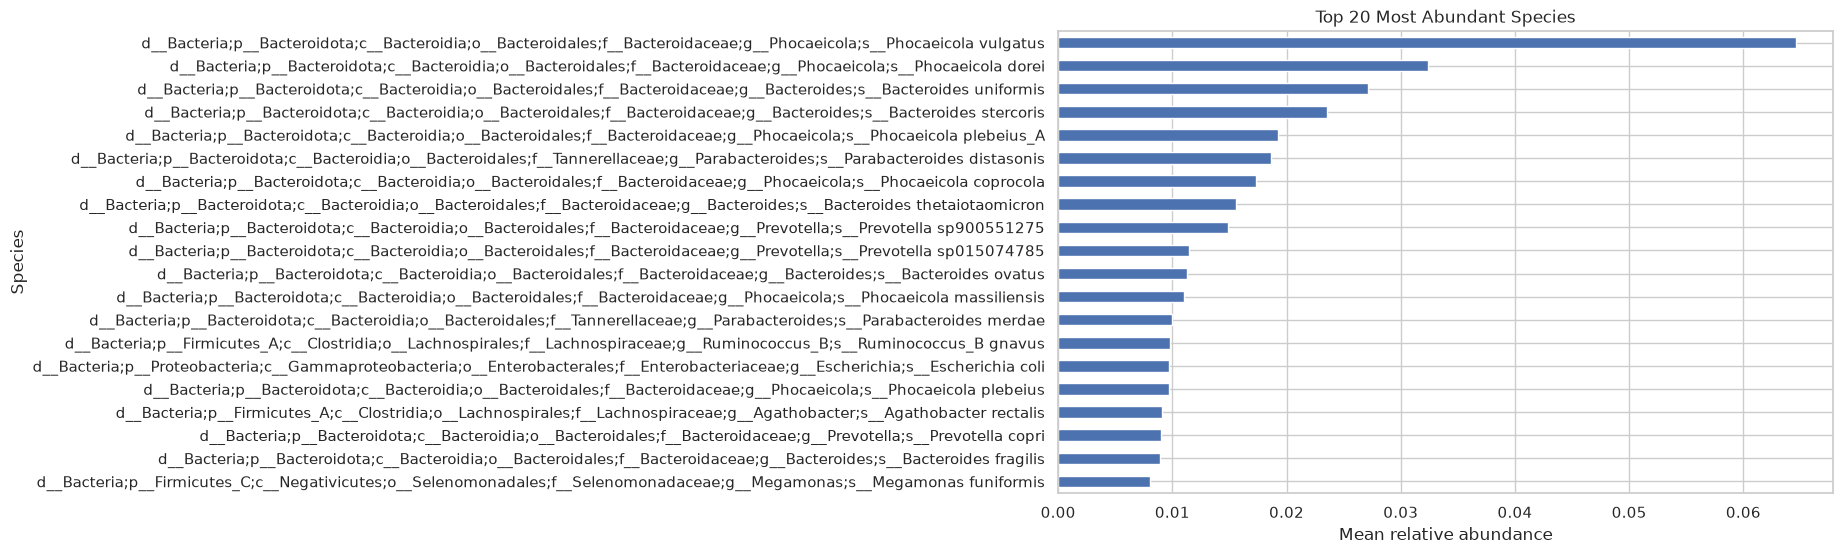

In [83]:
mean_abundance = species_filtered[keep_species].mean().sort_values(ascending=False)

top20_taxa = mean_abundance.head(20)

plt.figure(figsize=(10,6))
top20_taxa.sort_values().plot(kind="barh")

plt.xlabel("Mean relative abundance")
plt.ylabel("Species")
plt.title("Top 20 Most Abundant Species")
plt.tight_layout()
plt.show()

1. The gut microbiome is dominated by Bacteroidota species. The most abundant species belong predominantly to the phylum Bacteroidota, particularly the genera Phocaeicola, Bacteroides, Parabacteroides, and Prevotella. These genera are well-known members of the healthy human gut microbiome and are commonly reported as dominant taxa in fecal metagenomic studies.

2. Phocaeicola vulgatus is the dominant species.
Phocaeicola vulgatus (formerly classified as Bacteroides vulgatus) exhibited the highest mean relative abundance, accounting for approximately 6–7% of the microbial community on average. This species is a common commensal bacterium in the human gut and its dominance is consistent with previous gut microbiome studies.

3. Several abundant taxa belong to the same bacterial families.
Many of the top-ranked species belong to the Bacteroidaceae family, indicating that this family contributes substantially to the microbial composition across the study cohort. Other frequently observed taxa include members of the Tannerellaceae, Lachnospiraceae, Ruminococcaceae, and Enterobacteriaceae families.

4. No single species dominates the entire microbiome.
Although Phocaeicola vulgatus is the most abundant species, its mean abundance remains below 10%. This indicates that the gut microbiome is a complex ecosystem composed of many moderately abundant species rather than being dominated by a single microorganism.

In [84]:
species_processed = pd.DataFrame(
    X_scaled,
    columns=keep_species,
    index=species_filtered.index
)

species_processed.insert(0, "Sample", species_filtered["Sample"].values)

# **Phase 3 — Metabolomics Analysis**

## Dataset Overview

In [86]:
mtb = pd.read_csv("data/mtb.tsv", sep="\t")

assert (mtb["Sample"].values == metadata["Sample"].values).all(), \
    "Sample order mismatch: mtb vs metadata — do not proceed until fixed"

print("Shape:", mtb.shape)
print()

print("Number of samples:", mtb.shape[0])
print("Number of metabolites:", mtb.shape[1]-1)

mtb.head()

mtb.info()

AssertionError: Sample order mismatch: mtb vs metadata — do not proceed until fixed

In [87]:
meta_samples = set(metadata["Sample"])
mtb_samples = set(mtb["Sample"])
print("Same set of samples:", meta_samples == mtb_samples)
print("In metadata but not mtb:", meta_samples - mtb_samples)
print("In mtb but not metadata:", mtb_samples - meta_samples)
print("metadata shape:", metadata.shape[0], "| mtb shape:", mtb.shape[0])

Same set of samples: True
In metadata but not mtb: set()
In mtb but not metadata: set()
metadata shape: 347 | mtb shape: 347


In [88]:
mtb = mtb.set_index("Sample").loc[metadata["Sample"]].reset_index()
assert (mtb["Sample"].values == metadata["Sample"].values).all(), \
    "Still mismatched after reorder"

/tmp/ipykernel_1012100/2506479079.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  mtb = mtb.set_index("Sample").loc[metadata["Sample"]].reset_index()


## Quality Check

In [89]:
# Missing values
print("Total missing values:",
      mtb.isna().sum().sum())

# Duplicate samples
print("Duplicate Sample IDs:",
      mtb["Sample"].duplicated().sum())

print("Unique Sample IDs:",
      mtb["Sample"].nunique())

Total missing values: 0
Duplicate Sample IDs: 0
Unique Sample IDs: 347


## Distribution Assessment

In [90]:
representative = "C00212_Adenosine"

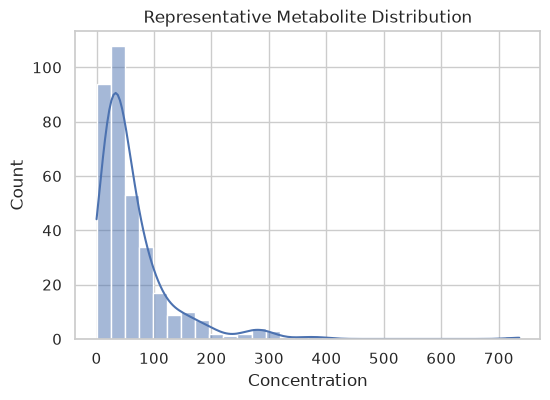

In [91]:
plt.figure(figsize=(6,4))

sns.histplot(
    mtb[representative],
    bins=30,
    kde=True
)

plt.title("Representative Metabolite Distribution")
plt.xlabel("Concentration")
plt.show()

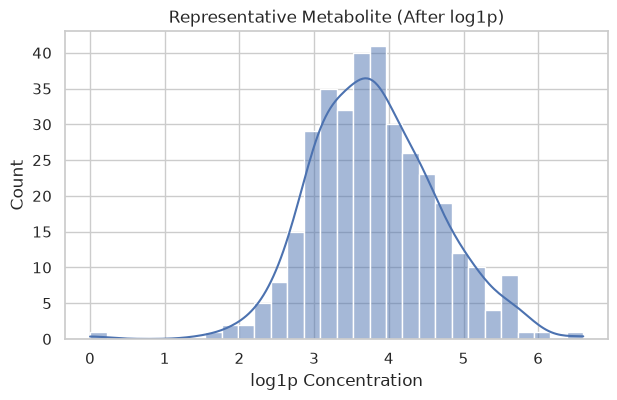

In [92]:
plt.figure(figsize=(7,4))

sns.histplot(
    np.log1p(mtb[representative]),
    bins=30,
    kde=True
)

plt.title("Representative Metabolite (After log1p)")
plt.xlabel("log1p Concentration")

plt.show()

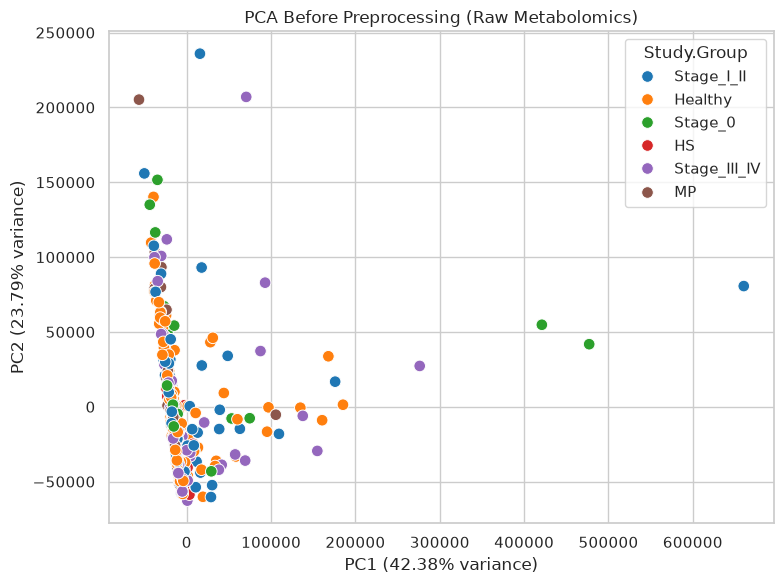

Explained variance ratio:
[0.42375495 0.2379338 ]


In [93]:
from sklearn.decomposition import PCA

# Remove Sample ID
X_raw = mtb.drop(columns="Sample")

# PCA on raw metabolomics data
pca_raw = PCA(n_components=2)
pca_raw_scores = pca_raw.fit_transform(X_raw)

# Build dataframe
pca_raw_df = pd.DataFrame({
    "PC1": pca_raw_scores[:,0],
    "PC2": pca_raw_scores[:,1]
})

# Add disease labels
pca_raw_df["Study.Group"] = metadata["Study.Group"].values

# Plot
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=pca_raw_df,
    x="PC1",
    y="PC2",
    hue="Study.Group",
    palette="tab10",
    s=70
)

plt.title("PCA Before Preprocessing (Raw Metabolomics)")
plt.xlabel(f"PC1 ({pca_raw.explained_variance_ratio_[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({pca_raw.explained_variance_ratio_[1]*100:.2f}% variance)")

plt.tight_layout()
plt.show()

print("Explained variance ratio:")
print(pca_raw.explained_variance_ratio_)

The first principal component alone explains over 42% of the total variance, indicating that a small number of highly abundant metabolites dominate the data. The PCA plot shows several samples located far from the main cluster, reflecting the influence of extreme metabolite concentrations. At this stage, the principal components primarily capture differences in metabolite magnitude rather than underlying biological variation between disease groups.

## Preprocessing

In [94]:
mtb_log = mtb.copy()

metabolite_cols = mtb.columns[1:]

mtb_log[metabolite_cols] = np.log1p(
    mtb_log[metabolite_cols]
)

In [95]:
#standardisation
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    mtb_log[metabolite_cols]
)

In [99]:
# Distance from center
center = umap_df[["UMAP1", "UMAP2"]].mean()

umap_df["Distance_from_center"] = np.sqrt(
    (umap_df["UMAP1"] - center["UMAP1"])**2 +
    (umap_df["UMAP2"] - center["UMAP2"])**2
)

# Top 10 potential outliers
outliers = umap_df.nlargest(10, "Distance_from_center")

outliers

,UMAP1,UMAP2,Study.Group,Distance_from_center
0,5.497066,-1.122444,Stage_I_II,3.765225
15,5.511496,-1.176152,Stage_0,3.764371
2,5.460090,-1.175402,Healthy,3.715063
10,5.439585,-1.227893,Healthy,3.681378
4,5.448794,-1.456781,Healthy,3.637829
18,5.298879,-1.134095,Healthy,3.572045
7,5.326367,-1.281335,Healthy,3.558249
36,5.289319,-1.157531,Healthy,3.556085
1,5.283629,-1.312928,Healthy,3.508962
20,5.273964,-1.289029,HS,3.505610


In [100]:
metadata.loc[outliers.index]

,Dataset,Sample,Subject,Study.Group,Age,Age.Units,Gender,BMI,DOI,Publication.Name,Stage,Brinkman Index,Alcohol,Tumor location,Shared.w.ERAWIJANTARI_2020
0,YACHIDA_CRC_2019,10021,10021,Stage_I_II,57,Years,Male,26.880952,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,I,130,993.00,Left colon,False
15,YACHIDA_CRC_2019,10055,10055,Stage_0,56,Years,Female,17.481790,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,0,155,0.00,Left colon,False
2,YACHIDA_CRC_2019,10025,10025,Healthy,40,Years,Male,25.000000,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,400,993.00,-,True
10,YACHIDA_CRC_2019,10040,10040,Healthy,66,Years,Female,21.641274,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,121.95,-,False
4,YACHIDA_CRC_2019,10031,10031,Healthy,77,Years,Male,24.464602,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,300,813.00,-,False
18,YACHIDA_CRC_2019,10060,10060,Healthy,73,Years,Female,20.703125,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.00,-,True
7,YACHIDA_CRC_2019,10036,10036,Healthy,64,Years,Female,21.155294,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,0,0.00,-,True
36,YACHIDA_CRC_2019,10100,10100,Healthy,70,Years,Male,23.661439,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,400,294.45,-,True
1,YACHIDA_CRC_2019,10023,10023,Healthy,65,Years,Male,26.562500,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,660,0.00,-,False
20,YACHIDA_CRC_2019,10066,10066,HS,56,Years,Male,22.204082,10.1038/s41591-019-0458-7,Metagenomic and metabolomic analyses reveal di...,-,330,240.00,-,False


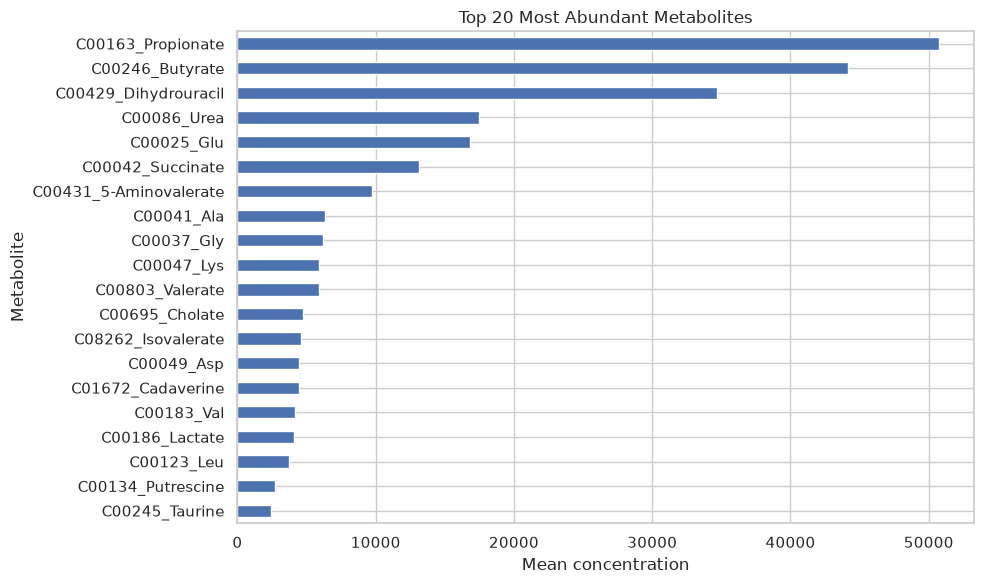

In [101]:
mean_metabolites = mtb[metabolite_cols].mean().sort_values(ascending=False)

top20_metabolites = mean_metabolites.head(20)

plt.figure(figsize=(10,6))
top20_metabolites.sort_values().plot(kind="barh")

plt.xlabel("Mean concentration")
plt.ylabel("Metabolite")
plt.title("Top 20 Most Abundant Metabolites")
plt.tight_layout()
plt.show()